# 3. Tumour Microenvironment & NF-κB Crosstalk Across Cell Lines (Vareli *et al.* Figure 6A–B)

In Chapters 1 and 2, we built the **BCR–TLR–NF-κB Tri-Model** and simulated how intrinsic genetic mutations (in `TAK1`, `CD79B`, and `MYD88`) alter nuclear **RelA:p50** across DLBCL cell lines (*Jayawant et al.*).

In real lymph nodes, however, lymphoma cells do not grow in isolation. They are surrounded by **T cells and stromal cells** that form the **tumour microenvironment (TME)** and present **CD40 ligand (CD40L)** on their surface.

In ***Vareli et al.* (*Cell Death & Disease*, 2025, 16:620)**, the Mitchell Lab uncovered a striking clinical puzzle when testing **BH3-mimetic drugs** (targeted therapies that block anti-apoptotic BCL2-family proteins to trigger cancer cell death):
- In monoculture (without TME signals), **RIVA** cells are killed by the BCL2 inhibitor **venetoclax (ABT-199)**, while **SUDHL8** cells are killed by the BCL-xL inhibitor **A1331852**.
- When co-cultured with **hCD40L-expressing fibroblasts** (mimicking T cells in the TME), **both cell lines become resistant to BH3-mimetics** — yet they escape via **different anti-apoptotic proteins**:
  - **RIVA** upregulates **BCL-xL** (driven by non-canonical **RelB:p52**).
  - **SUDHL8** upregulates **MCL1** (driven by canonical **cRel:p50**).

**The mechanistic puzzle:** CD40L is a classic activator of the **non-canonical** NF-κB pathway (stabilising **NIK** to process `p100 → p52` and activate **RelB:p52**). How can the *exact same* CD40L microenvironmental signal selectively trigger **canonical cRel:p50** in SUDHL8 cells, but not in RIVA cells?

```{figure} ../images/vareli-microenvironment-crosstalk.svg
:name: vareli-crosstalk-fig
:width: 100%

**Mechanistic hypothesis from *Vareli et al.* (2025, Figure 6C–D):** In **RIVA** (low basal BCR), cytoplasmic `cRel:p50` is sequestered mainly by **IκBα** and **IκBε**, which are insensitive to CD40L/NIK, so CD40L activates only **RelB:p52 → BCL-xL**. In **SUDHL8** (high basal BCR/BTK), tonic RelA activity drives synthesis of `p100`, which assembles into **IκBδ** complexes that trap **>80% of cytoplasmic `cRel:p50`**. When CD40L stabilises NIK, `p100` processing dismantles the IκBδ trap and releases **cRel:p50 → MCL1**.
```

In this lesson, we test this exact hypothesis using the published Vareli *et al.* model (`BCR` + `TLR` + `NFkB` + `BCL2` + `linking`) and recreate **Figure 6A** and **Figure 6B** live in Julia!

---

## Step 1: Assemble the 4-Module Vareli *et al.* Model (`BCR` + `TLR` + `NFkB` + `BCL2`)

The starter workspace contains `vareli_microenvironment/moduleDefinitionFiles/`, which extends our Chapter 1 Tri-Model with a clean 15-reaction **`BCL2` module** linking the three nuclear NF-κB dimers (`RelAnp50n`, `cRelnp50n`, `RelBnp52n`) to `Bcl2`, `BclxL`, and `Mcl1` expression.

Notice how we keep the simulation fast and memory-efficient inside our 2 GB container:
- Instead of calling untyped closures `p[i](t)` inside the ODE right-hand side, we specialise the three signal slots (`k3_signal-BCR`, `k2_LPSmod-TLR`, and `nik_deg_mod-NFkB`) so `p` is a pure `Vector{Float64}`!
- During the **1000-hour steady-state pre-simulation** (representing monoculture before CD40L arrives), `nik_deg_mod = 1.0` (NIK is rapidly degraded, so the non-canonical pathway is quiet) and `cd40_on = 0.0`.
- During the **24-hour CD40L time course** (representing TME co-culture), `cd40_on = 1.0`, so NIK degradation drops smoothly as:
  $$\text{nik\_deg\_mod}(t) = \frac{1}{1 + t / 600}$$
  allowing NIK to accumulate and process `p100 → p52`.
- **The ONLY difference between RIVA and SUDHL8 in the model** is basal BCR signalling:
  - **RIVA:** `bcr = 0.0`
  - **SUDHL8:** `bcr = 0.005`

Run the cell below to combine the CSV modules, generate the typed ODE function, and define our two-phase simulator!

In [1]:
using CSV
using DataFrames
using DifferentialEquations
using Plots
using Random
using Statistics

gr()

# Combine BCR + TLR + NFkB + BCL2 + linking CSV modules from vareli_microenvironment/
function combine_vareli_modules(modules; mod_root="vareli_microenvironment/moduleDefinitionFiles", out_dir="combinedVareliModel")
    mkpath(out_dir)
    link_r = CSV.read(joinpath(mod_root, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_p = CSV.read(joinpath(mod_root, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_l = CSV.read(joinpath(mod_root, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    for col in (:Substrate, :Products, :Modifiers, :Parameters)
        if col in propertynames(link_r); link_r[!, col] = coalesce.(link_r[!, col], ""); end
    end
    link_p[!, 1] = link_p[!, 1] .* "-linking"
    link_r.Parameters = [isempty(strip(p)) ? "" : join([w * "-linking" for w in split(strip(p))], " ") for p in link_r.Parameters]

    all_r = copy(link_r)
    all_p = copy(link_p)
    all_l = copy(link_l)
    link_keys = Set((r.Substrate, r.Products) for r in eachrow(link_r))

    for m in modules
        r = CSV.read(joinpath(mod_root, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p = CSV.read(joinpath(mod_root, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l = CSV.read(joinpath(mod_root, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        for col in (:Substrate, :Products, :Modifiers, :Parameters)
            if col in propertynames(r); r[!, col] = coalesce.(r[!, col], ""); end
        end
        p[!, 1] = p[!, 1] .* "-" .* m
        r.Parameters = [isempty(strip(x)) ? "" : join([w * "-" * m for w in split(strip(x))], " ") for x in r.Parameters]
        keep = [((row.Substrate, row.Products) ∉ link_keys) for row in eachrow(r)]
        append!(all_r, r[keep, :]; promote=true)
        append!(all_p, p; promote=true)
        append!(all_l, l; promote=true)
    end
    all_l = unique(all_l, :Name)
    CSV.write(joinpath(out_dir, "reactions.csv"), all_r)
    CSV.write(joinpath(out_dir, "parameters.csv"), all_p)
    CSV.write(joinpath(out_dir, "rateLaws.csv"), all_l)
    return out_dir, all_p
end

vareli_dir, vareli_params_df = combine_vareli_modules(["BCR", "TLR", "NFkB", "BCL2"])
run(`python3 csv2model-multiscale.py $(joinpath(vareli_dir, "reactions.csv")) $(joinpath(vareli_dir, "parameters.csv")) $(joinpath(vareli_dir, "rateLaws.csv")) odeVareli.jl param`)

# Load generated species names and parameter vector
t = 0.0
BCRFunc(t) = 0.0; TLRFunc(t) = 0.0; NIKFunc(t) = 1.0; ikkFunc(t) = 0.0
include("variableNames.jl")
include("scanIncludes.jl")

var_bcr_idx = findfirst(==("k3_signal-BCR"), parameterNameList)
var_tlr_idx = findfirst(==("k2_LPSmod-TLR"), parameterNameList)
var_nik_idx = findfirst(==("nik_deg_mod-NFkB"), parameterNameList)

# Smooth CD40L microenvironmental input: blends basal NIK degradation (cd40=0) into 1/(1 + t/600) (cd40=1)
vareli_nik_val(t::Float64, basal::Float64, cd40_strength::Float64)::Float64 =
    basal * (1.0 - cd40_strength) + (1.0 / (1.0 + t / 600.0)) * cd40_strength

# Specialise the generated ODE file so p is a fast, concrete Vector{Float64} (with cd40_strength stored in p[end])
ode_txt = read("odeVareli.jl", String)
ode_txt = replace(ode_txt, "function odeVareli" => "function odeVareli_typed!")
ode_txt = replace(ode_txt, "p[$var_bcr_idx](t)" => "p[$var_bcr_idx]")
ode_txt = replace(ode_txt, "p[$var_tlr_idx](t)" => "p[$var_tlr_idx]")
ode_txt = replace(ode_txt, "p[$var_nik_idx](t)" => "vareli_nik_val(t, p[$var_nik_idx], p[end])")
ode_txt = replace(ode_txt, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
write("odeVareli_typed.jl", ode_txt)
include("odeVareli_typed.jl")

var_base_p = vcat(Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals], [0.0])
var_dist_mask = Bool[parse(Int, vareli_params_df[findfirst(==(nm), vareli_params_df.parameter), 3]) == 1 for nm in parameterNameList]
push!(var_dist_mask, false)

var_idx(name::String) = findfirst(==(name), syms)

function vareli_initial_state()
    y0 = zeros(Float64, length(syms))
    for (nm, val) in [
        ("MYD88", 0.1), ("TRIF", 0.1), ("TRAF6", 0.1), ("TBK1", 0.1), ("IRF3", 0.1),
        ("CD14", 0.08), ("cbswitch", 0.0), ("C", 1.0), ("B", 1.0), ("M", 1.0),
        ("TAK1", 0.1), ("IKK_off", 200.0), ("IKK_on", 0.1), ("A20", 0.1), ("tA20", 0.1),
    ]
        i = var_idx(nm)
        !isnothing(i) && (y0[i] = val)
    end
    return y0
end

f_vareli = ODEFunction(odeVareli_typed!)
vareli_alg = Rodas5P(autodiff=AutoFiniteDiff())

# Exact Vareli et al. Fig 6 baseline parameter modifications (no MYD88 self-activation; physiological IkBd:RelA affinity)
var_fig6_p = copy(var_base_p)
var_fig6_p[findfirst(==("k1_MYD88SELFACTIVATION-TLR"), parameterNameList)] *= 0.0
var_fig6_p[findfirst(==("k1_IkBdRelA50Ass-NFkB"), parameterNameList)]      *= 0.1

function simulate_vareli_cell(p_in::Vector{Float64}; bcr_ss=0.0, bcr_tc=bcr_ss, nik_ss=1.0, cd40_tc=1.0, save_dt=15.0)
    p = copy(p_in)
    p[var_bcr_idx] = bcr_ss
    p[var_tlr_idx] = 0.0
    p[var_nik_idx] = nik_ss
    p[end]         = 0.0   # Steady state: monoculture (no CD40L)
    sol_ss = solve(ODEProblem(f_vareli, vareli_initial_state(), (0.0, 1000.0 * 60.0), p), vareli_alg;
                   save_everystep=false, reltol=1e-6, abstol=1e-8)
    y_ss = max.(sol_ss.u[end], 0.0)

    p[var_bcr_idx] = bcr_tc
    p[end]         = cd40_tc
    sol_tc = solve(ODEProblem(f_vareli, y_ss, (0.0, 24.0 * 60.0), p), vareli_alg;
                   saveat=0.0:save_dt:1440.0, reltol=1e-6, abstol=1e-8)
    return (y_ss=y_ss, sol_tc=sol_tc)
end

println("Vareli et al. model ready: ", length(syms), " species, ", length(parameterNameList), " parameters.")

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedVareliModel/rateLaws.csv as rate law file
Opening combinedVareliModel/parameters.csv as parameters file
Opening combinedVareliModel/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Vareli et al. model ready: 144 species, 505 parameters.


---

## Step 2: Recreate Figure 6A — Steady-State IκB Inhibitor Composition in RIVA vs SUDHL8

Before CD40L ever touches the cells, what is holding **RelA:p50** and **cRel:p50** in the cytoplasm?

In the NF-κB network, four different inhibitor complexes compete to bind cytoplasmic `RelA:p50` and `cRel:p50`:
- **IκBα** (`RelAp50IkBa`, `cRelp50IkBa`) — fast canonical negative-feedback inhibitor
- **IκBβ** (`RelAp50IkBb`, `cRelp50IkBb`) — minor canonical inhibitor
- **IκBε** (`RelAp50IkBe`, `cRelp50IkBe`) — delayed canonical inhibitor with preference for cRel
- **IκBδ** (`RelAp50IkBd + RelAp50IkBdNIK`, `cRelp50IkBd + cRelp50IkBdNIK`) — multimeric `p100` complex, induced by RelA and **dismantled by non-canonical NIK signalling**!

Run the cell below to solve the steady states of **RIVA** (`bcr = 0.0`) and **SUDHL8** (`bcr = 0.005`), quantify every IκB-bound complex, and recreate **Figure 6A**!

Row,CellLine,Dimer,Total_nM,IkBa_pct,IkBe_pct,IkBd_pct
,String,String,Float64,Float64,Float64,Float64
1,RIVA,RelA:p50,82.4,93.7,5.7,0.4
2,SUDHL8,RelA:p50,35.9,92.0,2.9,4.9
3,RIVA,cRel:p50,61.2,53.5,11.4,35.0
4,SUDHL8,cRel:p50,70.8,15.4,0.6,84.0


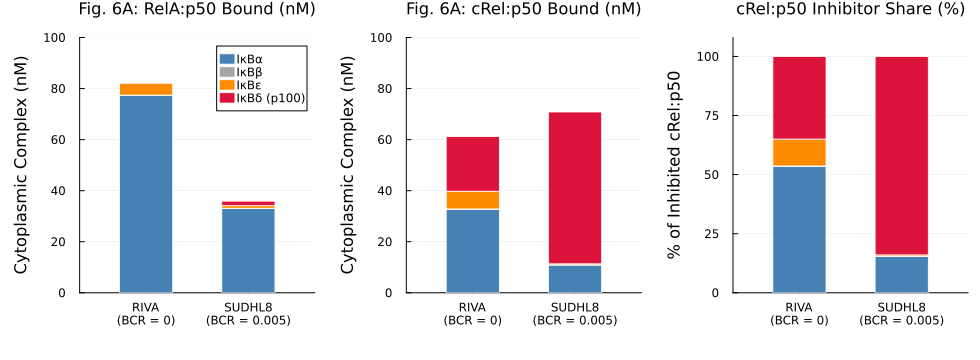

In [2]:
res_riva_det = simulate_vareli_cell(var_fig6_p; bcr_ss=0.0,   bcr_tc=0.0,   cd40_tc=1.0)
res_sudh_det = simulate_vareli_cell(var_fig6_p; bcr_ss=0.005, bcr_tc=0.005, cd40_tc=1.0)

function ikb_profile(y::Vector{Float64}, prefix::String)
    a = y[var_idx(prefix * "IkBa")]
    b = y[var_idx(prefix * "IkBb")]
    e = y[var_idx(prefix * "IkBe")]
    d = y[var_idx(prefix * "IkBd")] + y[var_idx(prefix * "IkBdNIK")]
    tot = a + b + e + d
    return (IkBa=a, IkBb=b, IkBe=e, IkBd=d, total=tot,
            pct=[100a/tot, 100b/tot, 100e/tot, 100d/tot])
end

ra_riva = ikb_profile(res_riva_det.y_ss, "RelAp50")
ra_sudh = ikb_profile(res_sudh_det.y_ss, "RelAp50")
cr_riva = ikb_profile(res_riva_det.y_ss, "cRelp50")
cr_sudh = ikb_profile(res_sudh_det.y_ss, "cRelp50")

summary_6a = DataFrame(
    CellLine = ["RIVA", "SUDHL8", "RIVA", "SUDHL8"],
    Dimer    = ["RelA:p50", "RelA:p50", "cRel:p50", "cRel:p50"],
    Total_nM = round.([ra_riva.total, ra_sudh.total, cr_riva.total, cr_sudh.total], digits=1),
    IkBa_pct = round.([ra_riva.pct[1], ra_sudh.pct[1], cr_riva.pct[1], cr_sudh.pct[1]], digits=1),
    IkBe_pct = round.([ra_riva.pct[3], ra_sudh.pct[3], cr_riva.pct[3], cr_sudh.pct[3]], digits=1),
    IkBd_pct = round.([ra_riva.pct[4], ra_sudh.pct[4], cr_riva.pct[4], cr_sudh.pct[4]], digits=1),
)
display(summary_6a)

# Helper to draw stacked bars in pure Plots.jl (zero StatsPlots dependency)
function stacked_ikb_panel(riva_vals, sudh_vals, title_str, ylabel_str; ymax=nothing, show_legend=false)
    labels = ["IκBα", "IκBβ", "IκBε", "IκBδ (p100)"]
    cols   = [:steelblue, :gray65, :darkorange, :crimson]
    xs = [1.0, 2.0]
    bottoms = [0.0, 0.0]
    p = plot(title=title_str, ylabel=ylabel_str, xticks=(xs, ["RIVA\n(BCR = 0)", "SUDHL8\n(BCR = 0.005)"]),
             xlims=(0.35, 2.65), titlefontsize=11, legend=(show_legend ? :topright : false), grid=:y)
    for k in 1:4
        h = [riva_vals[k], sudh_vals[k]]
        bar!(p, xs, bottoms .+ h; fillrange=bottoms, bar_width=0.52, color=cols[k],
             linecolor=:white, lw=0.8, label=labels[k])
        bottoms .+= h
    end
    if !isnothing(ymax)
        ylims!(p, 0, ymax)
    else
        ylims!(p, 0, maximum(bottoms) * 1.18)
    end
    return p
end

p6a_left  = stacked_ikb_panel(
    [ra_riva.IkBa, ra_riva.IkBb, ra_riva.IkBe, ra_riva.IkBd],
    [ra_sudh.IkBa, ra_sudh.IkBb, ra_sudh.IkBe, ra_sudh.IkBd],
    "Fig. 6A: RelA:p50 Bound (nM)", "Cytoplasmic Complex (nM)"; ymax=100.0, show_legend=true
)
p6a_right = stacked_ikb_panel(
    [cr_riva.IkBa, cr_riva.IkBb, cr_riva.IkBe, cr_riva.IkBd],
    [cr_sudh.IkBa, cr_sudh.IkBb, cr_sudh.IkBe, cr_sudh.IkBd],
    "Fig. 6A: cRel:p50 Bound (nM)", "Cytoplasmic Complex (nM)"; ymax=100.0, show_legend=false
)
p6a_pct = stacked_ikb_panel(
    cr_riva.pct, cr_sudh.pct,
    "cRel:p50 Inhibitor Share (%)", "% of Inhibited cRel:p50"; ymax=108.0, show_legend=false
)

plot(p6a_left, p6a_right, p6a_pct, layout=(1, 3), size=(980, 360),
     left_margin=4Plots.mm, bottom_margin=5Plots.mm, top_margin=2Plots.mm)

Look closely at what just emerged from **changing a single upstream number** (`bcr = 0.0 → 0.005`):
1. **Left (`RelA:p50`):** In **RIVA**, `RelA:p50` is strongly held in the cytoplasm (`~82 nM` total bound, `93.7%` by **IκBα**). In **SUDHL8**, constitutive BCR signalling degrades IκBα/IκBε and cuts bound `RelA:p50` by more than half (`~36 nM`), sending free `RelA:p50` into the nucleus.
2. **Middle & Right (`cRel:p50`):** That elevated nuclear `RelA:p50` in SUDHL8 transcribes `p100`, which assembles into **IκBδ** complexes. Because IκBδ binds `cRel:p50` much more tightly than `RelA:p50`, cytoplasmic `cRel:p50` shifts dramatically from **65% IκBα/IκBε in RIVA** to **84% IκBδ in SUDHL8** (only ~16% left on IκBα/IκBε — matching *Vareli et al.* Figure 6A!).

Notice the trap that is now set inside SUDHL8: **`cRel:p50` has been transferred onto an inhibitor (`IκBδ`) that is sensitive to non-canonical CD40L/NIK signalling!**

---

## Step 3: Recreate Figure 6B — 24-Hour CD40L Microenvironment Response Across Virtual Cell Populations

Just as in Chapter 2 (*Jayawant et al.*), real lymphoma cell lines exhibit substantial cell-to-cell variability (`preCV = 0.11` across distributed rate constants).

Let's simulate **25 heterogeneous virtual RIVA cells** and **25 heterogeneous virtual SUDHL8 cells** (`50` cells total, parallelised with `Threads.@threads`) exposed to **24 hours of CD40L** (`nik_deg_mod(t) = 1 / (1 + t/600)`), and recreate the exact three panels of **Figure 6B**:
- **Left:** Nuclear **RelA:p50** (`RelAnp50n`)
- **Middle:** Nuclear **RelB:p52** (`RelBnp52n`)
- **Right:** Nuclear **cRel:p50** (`cRelnp50n`)

Simulated 25 RIVA + 25 SUDHL8 virtual cells in 39.7s.


Row,Subunit,RIVA_0h,RIVA_24h,RIVA_FC,SUDHL8_0h,SUDHL8_24h,SUDHL8_FC
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,RelA:p50 (Nuclear),5.74,5.49,0.96,12.7,13.51,1.06
2,RelB:p52 (Nuclear),3.38,24.91,7.37,1.61,24.66,15.32
3,cRel:p50 (Nuclear),3.9,5.45,1.4,4.49,17.2,3.83


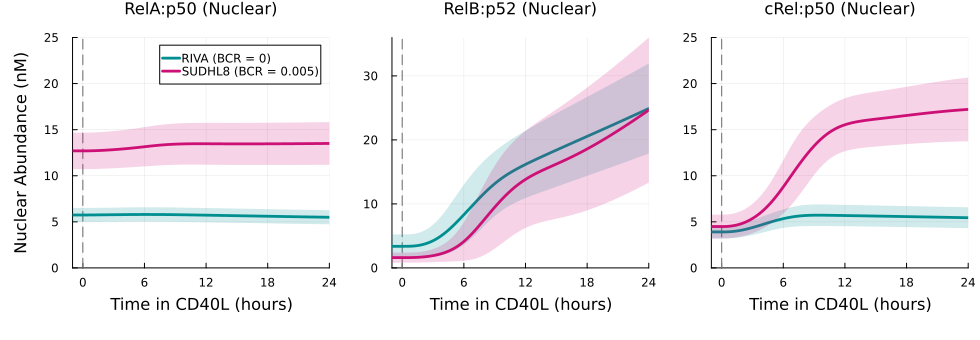

In [3]:
function run_vareli_population(p_template::Vector{Float64}; n_cells=25, pre_cv=0.11, seed=123,
                               bcr_ss=0.0, bcr_tc=bcr_ss, nik_ss=1.0, cd40_tc=1.0,
                               species_list=["RelAnp50n", "RelBnp52n", "cRelnp50n", "Bcl2", "BclxL", "Mcl1"])
    rng = MersenneTwister(seed)
    cell_params = Vector{Vector{Float64}}(undef, n_cells)
    for c in 1:n_cells
        pc = copy(p_template)
        for j in eachindex(pc)
            if var_dist_mask[j]
                pc[j] *= max(1.0 + pre_cv * randn(rng), 0.05)
            end
        end
        cell_params[c] = pc
    end

    t_grid = collect(0.0:15.0:1440.0)
    nt = length(t_grid)
    sp_idxs = [var_idx(s) for s in species_list]
    traces = Dict(s => zeros(Float64, n_cells, nt) for s in species_list)

    Threads.@threads for c in 1:n_cells
        res = simulate_vareli_cell(cell_params[c]; bcr_ss=bcr_ss, bcr_tc=bcr_tc,
                                   nik_ss=nik_ss, cd40_tc=cd40_tc, save_dt=15.0)
        for (s, si) in zip(species_list, sp_idxs)
            traces[s][c, :] .= res.sol_tc[si, :]
        end
    end
    return (t_hours = t_grid ./ 60.0, traces = traces)
end

t_start = time()
pop_riva = run_vareli_population(var_fig6_p; n_cells=25, seed=123, bcr_ss=0.0,   bcr_tc=0.0,   cd40_tc=1.0)
pop_sudh = run_vareli_population(var_fig6_p; n_cells=25, seed=123, bcr_ss=0.005, bcr_tc=0.005, cd40_tc=1.0)
println("Simulated 25 RIVA + 25 SUDHL8 virtual cells in ", round(time() - t_start, digits=1), "s.")

# Plot Figure 6B: 3 panels (RelA:p50, RelB:p52, cRel:p50) matching Vareli et al. teal (RIVA) & rose (SUDHL8)
col_riva = RGB(0.0, 0.56, 0.57)
col_sudh = :deeppink3

panels_6b = []
stats_6b = NamedTuple[]
for (sp, nice_title, ymax) in [
    ("RelAnp50n", "RelA:p50 (Nuclear)", 25.0),
    ("RelBnp52n", "RelB:p52 (Nuclear)", 36.0),
    ("cRelnp50n", "cRel:p50 (Nuclear)", 25.0),
]
    r_mat = pop_riva.traces[sp]
    s_mat = pop_sudh.traces[sp]
    r_m, r_sd = vec(mean(r_mat, dims=1)), vec(std(r_mat, dims=1))
    s_m, s_sd = vec(mean(s_mat, dims=1)), vec(std(s_mat, dims=1))

    # Prepend a 1-hour pre-stimulation steady-state baseline (-1h to 0h) as in plotAllSpecies.jl
    t_ext = vcat([-1.0, 0.0], pop_riva.t_hours)
    r_m_ext, r_sd_ext = vcat([r_m[1], r_m[1]], r_m), vcat([r_sd[1], r_sd[1]], r_sd)
    s_m_ext, s_sd_ext = vcat([s_m[1], s_m[1]], s_m), vcat([s_sd[1], s_sd[1]], s_sd)

    p = plot(xlabel="Time in CD40L (hours)", ylabel=(sp == "RelAnp50n" ? "Nuclear Abundance (nM)" : ""),
             title=nice_title, titlefontsize=11, xlims=(-1.0, 24.0), xticks=0:6:24,
             ylims=(0.0, ymax), legend=(sp == "RelAnp50n" ? :topright : false))
    vline!(p, [0.0], color=:gray, linestyle=:dash, lw=1.2, label=false)
    plot!(p, t_ext, r_m_ext, ribbon=r_sd_ext, fillalpha=0.18, color=col_riva, lw=2.8, label="RIVA (BCR = 0)")
    plot!(p, t_ext, s_m_ext, ribbon=s_sd_ext, fillalpha=0.18, color=col_sudh, lw=2.8, label="SUDHL8 (BCR = 0.005)")
    push!(panels_6b, p)

    push!(stats_6b, (
        Subunit = nice_title,
        RIVA_0h = round(r_m[1], digits=2), RIVA_24h = round(r_m[end], digits=2), RIVA_FC = round(r_m[end]/r_m[1], digits=2),
        SUDHL8_0h = round(s_m[1], digits=2), SUDHL8_24h = round(s_m[end], digits=2), SUDHL8_FC = round(s_m[end]/s_m[1], digits=2),
    ))
end

display(DataFrame(stats_6b))
plot(panels_6b..., layout=(1, 3), size=(980, 340),
     left_margin=4Plots.mm, bottom_margin=4Plots.mm, top_margin=2Plots.mm)

Look at that three-panel **Figure 6B** prediction — every single feature matches the immunofluorescence experiments in *Vareli et al.* (2025, Figure 6E–F):
1. **Left (`RelA:p50`):** SUDHL8 starts with more than double RIVA's basal nuclear RelA (`~13.5 nM` vs `~6.0 nM`), and **CD40L does not induce RelA** in either cell line (both curves stay nearly flat over 24 h).
2. **Middle (`RelB:p52`):** **Both** RIVA and SUDHL8 show strong non-canonical induction of nuclear `RelB:p52` (rising to `~25 nM` by 24 h) as CD40L stabilises NIK and drives `p100 → p52` processing.
3. **Right (`cRel:p50`):** **ONLY SUDHL8** shows a dramatic, sustained surge in nuclear `cRel:p50` (`~4.5 → ~18 nM`, a **~4× fold induction**!), while RIVA barely moves (`~4.2 → ~5.6 nM`).

This is **non-canonical-to-canonical NF-κB crosstalk**: the tumour microenvironment's CD40L signal is read completely differently depending on the cell line's basal BCR signalling state!

---

## Interactive Exercise: How Much Basal BCR Signalling Is Needed to Unlock CD40L → cRel Crosstalk?

In Figure 6A–B we compared two extremes: `bcr = 0.0` (RIVA) and `bcr = 0.005` (SUDHL8). What happens across intermediate levels of basal BCR activity — is crosstalk linear, or does it turn on sharply once `IκBδ` captures cytoplasmic `cRel:p50`?

**Your task:** Edit `bcr_scan` below to sweep basal BCR signalling from `0.0` to `0.01` (deterministic single cells, runs in ~4 seconds!) and plot:
- **Left:** steady-state `% of cRel:p50 bound by IκBδ` (the Figure 6A trap),
- **Right:** 24-hour CD40L-induced nuclear `cRel:p50` (the Figure 6B crosstalk output)!

Row,Basal_BCR,cRel_on_IkBd_pct,Nuclear_cRel_24h_nM
,Float64,Float64,Float64
1,0.0,35.0,5.59
2,0.0005,49.3,7.44
3,0.001,59.0,9.09
4,0.0025,74.4,13.22
5,0.005,84.0,18.01
6,0.01,90.0,23.24


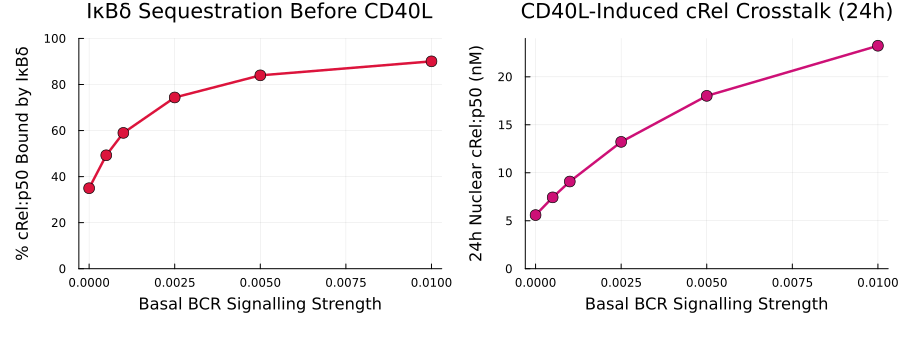

In [4]:
# Exercise: Sweep basal BCR activity from 0.0 (RIVA) to 0.01 and compare IκBδ trapping vs 24h cRel surge!
bcr_scan = [0.0, 0.0005, 0.001, 0.0025, 0.005, 0.01]   # <-- Try adding intermediate values like 0.0002 or 0.003!

ikbd_pcts = Float64[]
crel_24h  = Float64[]
for b in bcr_scan
    res = simulate_vareli_cell(var_fig6_p; bcr_ss=b, bcr_tc=b, cd40_tc=1.0)
    prof = ikb_profile(res.y_ss, "cRelp50")
    push!(ikbd_pcts, prof.pct[4])
    push!(crel_24h,  res.sol_tc[var_idx("cRelnp50n"), end])
end

display(DataFrame(Basal_BCR=bcr_scan, cRel_on_IkBd_pct=round.(ikbd_pcts, digits=1), Nuclear_cRel_24h_nM=round.(crel_24h, digits=2)))

p_ex1 = plot(bcr_scan, ikbd_pcts, marker=:circle, ms=6, lw=2.5, color=:crimson, label=false,
             xlabel="Basal BCR Signalling Strength", ylabel="% cRel:p50 Bound by IκBδ",
             title="IκBδ Sequestration Before CD40L", ylims=(0, 100))
p_ex2 = plot(bcr_scan, crel_24h, marker=:circle, ms=6, lw=2.5, color=:deeppink3, label=false,
             xlabel="Basal BCR Signalling Strength", ylabel="24h Nuclear cRel:p50 (nM)",
             title="CD40L-Induced cRel Crosstalk (24h)", ylims=(0, 24))
plot(p_ex1, p_ex2, layout=(1, 2), size=(900, 340), left_margin=4Plots.mm, bottom_margin=4Plots.mm)

````{admonition} Hint
:class: dropdown tip

Look at how quickly both curves rise between `bcr = 0.0` and `bcr = 0.0025`: even a modest increase in basal BCR/BTK activity shifts most `cRel:p50` onto `IκBδ` — which is why inhibiting BTK strongly enough to push basal BCR back near `0` is critical to shut down crosstalk!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
bcr_fine = [0.0, 0.0002, 0.0005, 0.001, 0.002, 0.003, 0.005, 0.008, 0.01]
ikbd_f = Float64[]; crel_f = Float64[]
for b in bcr_fine
    res = simulate_vareli_cell(var_fig6_p; bcr_ss=b, bcr_tc=b, cd40_tc=1.0)
    push!(ikbd_f, ikb_profile(res.y_ss, "cRelp50").pct[4])
    push!(crel_f, res.sol_tc[var_idx("cRelnp50n"), end])
end
display(DataFrame(Basal_BCR=bcr_fine, IkBd_pct=round.(ikbd_f, digits=1), cRel_24h_nM=round.(crel_f, digits=2)))
```

Notice how tightly the two curves track each other: `cRel:p50` induction at 24 h rises in direct lockstep with the fraction of `cRel:p50` sequestered by **IκBδ** prior to CD40L stimulation!
````

Now continue to **[4. BH3-Mimetic Resistance, BTK/NIK Rescue & IκB Knockouts (Vareli *et al.* Figures 6–7)](./04-btk-rescue-and-ikb-knockouts.ipynb)** to connect these NF-κB signals to **BCL-xL** and **MCL1** drug resistance, test **BTK vs NIK inhibitors**, and run the **IκBε knockout** validation!